In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/shivanipathak5143-web/EconoCasual/main/data/"

retail = pd.read_csv(BASE + "mock_retail.csv")
ite_scores = pd.read_csv(BASE + "ite_scores.csv")

print("Retail dataset shape:", retail.shape)
print("ITE scores shape:", ite_scores.shape)

display(retail.head())
display(ite_scores.head())

Retail dataset shape: (1000, 7)
ITE scores shape: (150, 5)


,customer_id,age,loyalty_score,past_orders,avg_order_value,discount,revenue
0,CUST_0001,59,1.54,18,97.24,1,175.47
1,CUST_0002,53,1.31,28,34.38,1,84.55
2,CUST_0003,33,5.20,2,190.57,0,169.94
3,CUST_0004,47,5.98,1,248.85,1,243.08
4,CUST_0005,46,3.66,10,88.52,0,118.99


,customer_id,ite,age,loyalty_score,avg_order_value
0,CUST_0001,6.70,59,1.54,97.24
1,CUST_0002,4.62,53,1.31,34.38
2,CUST_0003,15.77,33,5.20,190.57
3,CUST_0004,24.77,47,5.98,248.85
4,CUST_0005,17.18,46,3.66,88.52


In [56]:
# Check whether customer IDs are unique
print("Duplicate IDs in retail:", retail["customer_id"].duplicated().sum())
print("Duplicate IDs in ITE scores:", ite_scores["customer_id"].duplicated().sum())

# Check how many ITE customers exist in the retail dataset
matched_ids = set(retail["customer_id"]) & set(ite_scores["customer_id"])

print("Customers with ITE scores:", len(ite_scores))
print("Customers matched with retail:", len(matched_ids))
print("Customers without matching retail record:",
      len(set(ite_scores["customer_id"]) - set(retail["customer_id"])))

Duplicate IDs in retail: 0
Duplicate IDs in ITE scores: 0
Customers with ITE scores: 150
Customers matched with retail: 150
Customers without matching retail record: 0


ITE score summary:


,ite
count,150.00
mean,19.95
std,9.18
min,1.98
25%,12.68
50%,19.22
75%,27.62
max,39.66


Missing ITE scores: 0
Negative ITE scores: 0


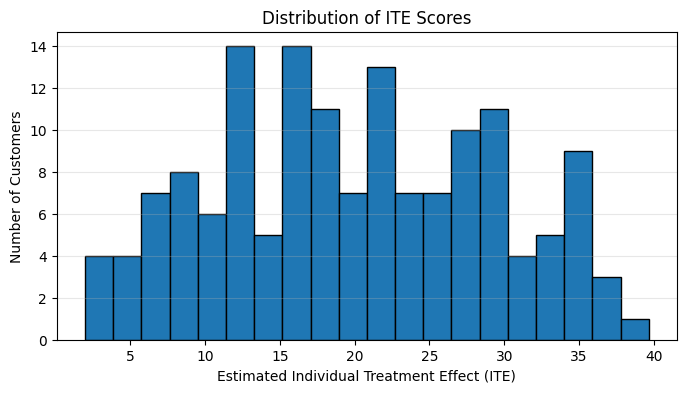

In [57]:
print("ITE score summary:")
display(ite_scores["ite"].describe().round(2))

print("Missing ITE scores:", ite_scores["ite"].isna().sum())
print("Negative ITE scores:", (ite_scores["ite"] < 0).sum())

plt.figure(figsize=(8, 4))
plt.hist(ite_scores["ite"], bins=20, edgecolor="black")
plt.xlabel("Estimated Individual Treatment Effect (ITE)")
plt.ylabel("Number of Customers")
plt.title("Distribution of ITE Scores")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [58]:
curve_existing = pd.read_csv(BASE + "uplift_curve.csv")

print("Shape:", curve_existing.shape)
print("Columns:", curve_existing.columns.tolist())

display(curve_existing.head(10))
display(curve_existing.tail(5))

Shape: (100, 4)
Columns: ['fraction_targeted', 'model_gain', 'oracle_gain', 'random_gain']


,fraction_targeted,model_gain,oracle_gain,random_gain
0,0.01,2333.23,2136.47,312.0
1,0.02,4613.23,4225.98,624.0
2,0.03,6839.86,6268.71,936.0
3,0.04,9012.98,8264.84,1248.0
4,0.05,11132.44,10214.55,1560.0
5,0.06,13198.09,12118.02,1872.0
6,0.07,15209.78,13975.44,2184.0
7,0.08,17167.34,15787.00,2496.0
8,0.09,19070.60,17552.89,2808.0
9,0.10,20919.40,19273.31,3120.0


,fraction_targeted,model_gain,oracle_gain,random_gain
95,0.96,35580.0,53385.0,29952.0
96,0.97,35130.0,53370.0,30264.0
97,0.98,34680.0,53355.0,30576.0
98,0.99,34230.0,53340.0,30888.0
99,1.00,33780.0,53325.0,31200.0


In [59]:
ranked = ite_scores.sort_values(
    "ite", ascending=False
).reset_index(drop=True)

print("Top 10 customers by predicted ITE:")
display(ranked[["customer_id", "ite"]].head(10))

print("Lowest 10 customers by predicted ITE:")
display(ranked[["customer_id", "ite"]].tail(10))

Top 10 customers by predicted ITE:


,customer_id,ite
0,CUST_0058,39.66
1,CUST_0056,37.28
2,CUST_0021,37.05
3,CUST_0133,37.01
4,CUST_0049,35.81
5,CUST_0047,35.47
6,CUST_0064,35.26
7,CUST_0115,35.23
8,CUST_0037,34.96
9,CUST_0121,34.41


Lowest 10 customers by predicted ITE:


,customer_id,ite
140,CUST_0031,6.09
141,CUST_0073,6.04
142,CUST_0013,5.71
143,CUST_0023,4.99
144,CUST_0002,4.62
145,CUST_0111,4.55
146,CUST_0118,3.75
147,CUST_0086,3.51
148,CUST_0090,2.48
149,CUST_0078,1.98


,fraction_targeted,model_gain
0,0.006667,39.66
1,0.013333,76.94
2,0.020000,113.99
3,0.026667,151.00
4,0.033333,186.81
5,0.040000,222.28
6,0.046667,257.54
7,0.053333,292.77
8,0.060000,327.73
9,0.066667,362.14


,fraction_targeted,model_gain
145,0.973333,2981.21
146,0.980000,2984.96
147,0.986667,2988.47
148,0.993333,2990.95
149,1.000000,2992.93


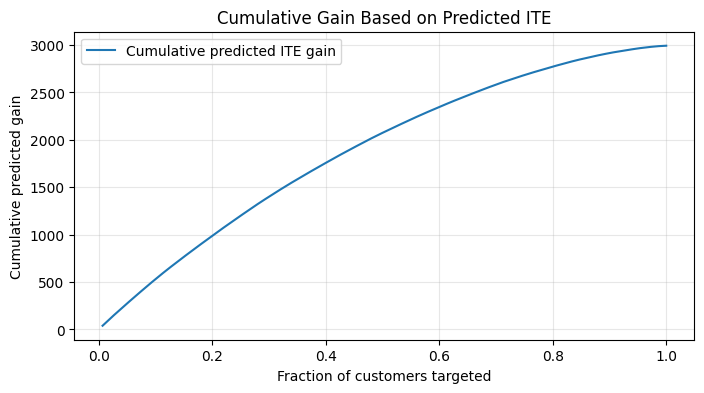

In [60]:
n = len(ranked)

ranked["fraction_targeted"] = (
    np.arange(1, n + 1) / n
)

ranked["model_gain"] = ranked["ite"].cumsum()

curve_model = ranked[
    ["fraction_targeted", "model_gain"]
].copy()

display(curve_model.head(10))
display(curve_model.tail(5))

plt.figure(figsize=(8, 4))
plt.plot(
    curve_model["fraction_targeted"],
    curve_model["model_gain"],
    label="Cumulative predicted ITE gain"
)
plt.xlabel("Fraction of customers targeted")
plt.ylabel("Cumulative predicted gain")
plt.title("Cumulative Gain Based on Predicted ITE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

,fraction_targeted,model_gain,random_gain
0,0.006667,39.66,19.952867
1,0.013333,76.94,39.905733
2,0.020000,113.99,59.858600
3,0.026667,151.00,79.811467
4,0.033333,186.81,99.764333
5,0.040000,222.28,119.717200
6,0.046667,257.54,139.670067
7,0.053333,292.77,159.622933
8,0.060000,327.73,179.575800
9,0.066667,362.14,199.528667


,fraction_targeted,model_gain,random_gain
145,0.973333,2981.21,2913.118533
146,0.980000,2984.96,2933.071400
147,0.986667,2988.47,2953.024267
148,0.993333,2990.95,2972.977133
149,1.000000,2992.93,2992.930000


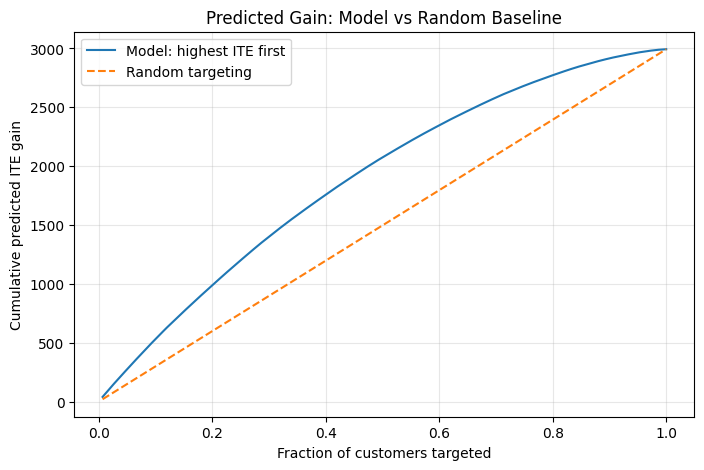

Total predicted ITE gain: 2992.93


In [61]:
# Expected gain when customers are targeted at random
total_predicted_gain = ranked["ite"].sum()

curve_model["random_gain"] = (
    curve_model["fraction_targeted"] * total_predicted_gain
)

display(curve_model.head(10))
display(curve_model.tail(5))

plt.figure(figsize=(8, 5))

plt.plot(
    curve_model["fraction_targeted"],
    curve_model["model_gain"],
    label="Model: highest ITE first"
)

plt.plot(
    curve_model["fraction_targeted"],
    curve_model["random_gain"],
    label="Random targeting",
    linestyle="--"
)

plt.xlabel("Fraction of customers targeted")
plt.ylabel("Cumulative predicted ITE gain")
plt.title("Predicted Gain: Model vs Random Baseline")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Total predicted ITE gain:", round(total_predicted_gain, 2))

In [62]:
# Build the required output schema
curve_final = curve_model[
    ["fraction_targeted", "model_gain", "random_gain"]
].copy()

# Ground-truth effects are missing, so oracle gain cannot be calculated
curve_final["oracle_gain"] = np.nan

curve_final = curve_final[
    ["fraction_targeted", "model_gain", "oracle_gain", "random_gain"]
]

# Save the CSV
output_file = "uplift_curve.csv"
curve_final.to_csv(output_file, index=False)

print("Saved:", output_file)
print("Shape:", curve_final.shape)
print("Columns:", curve_final.columns.tolist())
print("Oracle gain available:", curve_final["oracle_gain"].notna().any())

display(curve_final.head())
display(curve_final.tail())

Saved: uplift_curve.csv
Shape: (150, 4)
Columns: ['fraction_targeted', 'model_gain', 'oracle_gain', 'random_gain']
Oracle gain available: False


,fraction_targeted,model_gain,oracle_gain,random_gain
0,0.006667,39.66,NaN,19.952867
1,0.013333,76.94,NaN,39.905733
2,0.020000,113.99,NaN,59.858600
3,0.026667,151.00,NaN,79.811467
4,0.033333,186.81,NaN,99.764333


,fraction_targeted,model_gain,oracle_gain,random_gain
145,0.973333,2981.21,NaN,2913.118533
146,0.980000,2984.96,NaN,2933.071400
147,0.986667,2988.47,NaN,2953.024267
148,0.993333,2990.95,NaN,2972.977133
149,1.000000,2992.93,NaN,2992.930000


## Results and Limitations

The 150 customers with available ITE scores were ranked in descending
order of predicted treatment effect.

The cumulative predicted gain curve is compared with an expected
random-targeting baseline. The model-ranked curve lies above the
random baseline for partial targeting fractions in this dataset.

These gains are based on predicted ITE scores, not observed causal
effects, so they should not be interpreted as measured business impact.

The oracle gain curve could not be computed because true_effect.csv
is absent from the shared repository. Oracle comparison requires
verified ground-truth treatment effects and must not be replaced
with invented values.

In [63]:
# Verify the saved CSV
check = pd.read_csv("uplift_curve.csv")

print("Shape:", check.shape)
print("Columns:", check.columns.tolist())
print("Missing oracle values:", check["oracle_gain"].isna().sum())
print("Model gain always increases:",
      check["model_gain"].is_monotonic_increasing)
print("Random gain always increases:",
      check["random_gain"].is_monotonic_increasing)
print("Final model gain:", round(check["model_gain"].iloc[-1], 2))
print("Final random gain:", round(check["random_gain"].iloc[-1], 2))

Shape: (150, 4)
Columns: ['fraction_targeted', 'model_gain', 'oracle_gain', 'random_gain']
Missing oracle values: 150
Model gain always increases: True
Random gain always increases: True
Final model gain: 2992.93
Final random gain: 2992.93
